# Comparación de algoritmos de aprendizaje supervisado: KNN, SVM y MLP

**Problema:** clasificación de tumores de mama en **benignos** y **malignos**  
**Dataset:** Wisconsin Diagnostic Breast Cancer (WDBC)  
**Entorno:** Python · Google Colab · scikit-learn

---

## Fase 1. Introducción

### Objetivo
Implementar, entrenar, evaluar y comparar tres algoritmos de aprendizaje supervisado sobre el mismo conjunto de datos y con la misma partición de entrenamiento y prueba, para determinar cuál ofrece mejores resultados y justificar la elección con métricas y análisis.

### Algoritmos

| Algoritmo | Idea principal |
|---|---|
| **KNN** (K-Nearest Neighbors) | Clasifica una muestra según la clase mayoritaria de sus *k* vecinos más cercanos en el espacio de características. |
| **SVM** (Support Vector Machine) | Busca la frontera de decisión con mayor margen entre clases; con kernel RBF puede separar fronteras no lineales. |
| **MLP** (Perceptrón multicapa) | Red neuronal artificial con capas ocultas que aprende combinaciones no lineales de las variables mediante retropropagación. |

### Problema de clasificación
Clasificación **binaria** a partir de 30 características numéricas calculadas sobre imágenes digitalizadas de aspirados con aguja fina. La **clase positiva es la maligna (M)**, por lo que Precision, Recall y F1-score se interpretan respecto a los tumores malignos.

## Fase 2. Carga y exploración del dataset

### 2.1 Configuración del entorno
Se importan las bibliotecas y se fija la semilla de aleatoriedad (`random_state=42`) para garantizar reproducibilidad.

In [1]:
import os
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display, Markdown

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")

Python 3.12.3 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4


### 2.2 Carga del dataset
El archivo `wdbc.data` **no incluye encabezados**; según `wdbc.names`, contiene: `id`, `diagnosis` (M = maligno, B = benigno) y 30 variables numéricas (10 características × media, error estándar y valor "worst"). Los nombres de columnas se asignan siguiendo esa documentación.

La celda busca el archivo en `data/`; si no existe, intenta descargarlo del repositorio UCI y, como último recurso, solicita subirlo manualmente en Colab.

In [2]:
# Nombres de columnas según wdbc.names (campos 3-12: media, 13-22: error estándar, 23-32: worst)
BASE_FEATURES = ["radius", "texture", "perimeter", "area", "smoothness",
                 "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
COLUMNS = (["id", "diagnosis"]
           + [f"{f}_mean" for f in BASE_FEATURES]
           + [f"{f}_se" for f in BASE_FEATURES]
           + [f"{f}_worst" for f in BASE_FEATURES])

LOCAL_PATHS = ["../data/wdbc.data", "data/wdbc.data", "wdbc.data", "/content/wdbc.data"]
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"


def load_wdbc():
    """Devuelve (DataFrame, descripción de la fuente)."""
    for path in LOCAL_PATHS:
        if os.path.exists(path):
            return pd.read_csv(path, header=None, names=COLUMNS), path
    try:
        return pd.read_csv(UCI_URL, header=None, names=COLUMNS), "UCI Machine Learning Repository"
    except Exception:
        try:
            from google.colab import files  # solo disponible en Colab
            print("Sube el archivo wdbc.data proporcionado por el docente.")
            uploaded = files.upload()
            name = next(iter(uploaded))
            return pd.read_csv(name, header=None, names=COLUMNS), name
        except ImportError:
            raise FileNotFoundError("No se encontró wdbc.data. Colócalo en la carpeta data/.")


df, source = load_wdbc()
print("Fuente de datos:", source)
assert df.shape[1] == len(COLUMNS), "El archivo no tiene el número de columnas esperado (32)."

Fuente de datos: ../data/wdbc.data


### 2.3 Primeras filas

In [3]:
display(df.head())

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 2.4 Dimensiones, tipos de variables, valores nulos y duplicados

In [4]:
print(f"Registros: {df.shape[0]} | Columnas: {df.shape[1]}")

numeric_cols = df.select_dtypes(include=np.number).columns.drop("id").tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print(f"\nVariables numéricas predictoras: {len(numeric_cols)}")
print(f"Variables categóricas: {categorical_cols} (variable objetivo)")
print("Identificador (no se usa como predictor): ['id']")

print(f"\nValores nulos totales: {int(df.isna().sum().sum())}")
print(f"Filas duplicadas (completas): {int(df.duplicated().sum())}")
print(f"Identificadores duplicados: {int(df['id'].duplicated().sum())}")

display(df.dtypes.value_counts().rename("columnas").to_frame().rename_axis("tipo de dato"))

Registros: 569 | Columnas: 32

Variables numéricas predictoras: 30
Variables categóricas: ['diagnosis'] (variable objetivo)
Identificador (no se usa como predictor): ['id']

Valores nulos totales: 0
Filas duplicadas (completas): 0
Identificadores duplicados: 0


,columnas
tipo de dato,
float64,30
int64,1
str,1


### 2.5 Variable objetivo y distribución de clases
La variable objetivo es `diagnosis`: **B** (benigno) y **M** (maligno).

,registros,porcentaje (%)
diagnosis,,
B,357,62.74
M,212,37.26


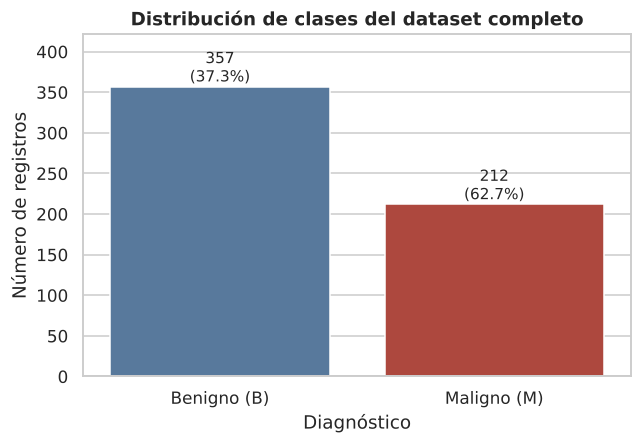

In [5]:
class_counts = df["diagnosis"].value_counts()
class_pct = df["diagnosis"].value_counts(normalize=True) * 100
display(pd.DataFrame({"registros": class_counts, "porcentaje (%)": class_pct.round(2)}))

order = ["B", "M"]
labels = {"B": "Benigno (B)", "M": "Maligno (M)"}
fig, ax = plt.subplots(figsize=(6, 4.2))
sns.countplot(data=df, x="diagnosis", hue="diagnosis", order=order,
              palette={"B": "#4c78a8", "M": "#c0392b"}, legend=False, ax=ax)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([labels[c] for c in order])
for p, c in zip(ax.patches, order):
    ax.annotate(f"{int(p.get_height())}\n({class_pct[c]:.1f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Distribución de clases del dataset completo")
ax.set_xlabel("Diagnóstico")
ax.set_ylabel("Número de registros")
ax.set_ylim(0, class_counts.max() * 1.18)
plt.tight_layout()
plt.show()

## Fase 3. Preparación de los datos

### 3.1 Separación de X e y y codificación de la clase
- `X`: las 30 características numéricas (se excluyen `id` y `diagnosis`; el identificador no aporta información clínica y causaría ruido).
- `y`: `diagnosis` codificada de forma explícita: **B = 0** y **M = 1**, de modo que la clase positiva sea la **maligna**.

In [6]:
CLASS_MAP = {"B": 0, "M": 1}
CLASS_NAMES = ["Benigno", "Maligno"]
POS_LABEL = 1  # clase maligna

X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"].map(CLASS_MAP)
assert y.notna().all(), "Hay etiquetas fuera de {B, M}."

print("Codificación:", CLASS_MAP, "-> clase positiva (1) = Maligno")
print("Forma de X:", X.shape, "| Forma de y:", y.shape)

Codificación: {'B': 0, 'M': 1} -> clase positiva (1) = Maligno
Forma de X: (569, 30) | Forma de y: (569,)


### 3.2 División entrenamiento / prueba
Una **única** partición 80/20, estratificada y con `random_state=42`. Los tres algoritmos usan exactamente estos mismos conjuntos.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

split_summary = pd.DataFrame({
    "registros": [len(y_train), len(y_test)],
    "benignos": [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "malignos": [int((y_train == 1).sum()), int((y_test == 1).sum())],
    "% malignos": [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)],
}, index=["Entrenamiento (80%)", "Prueba (20%)"])
display(split_summary)

,registros,benignos,malignos,% malignos
Entrenamiento (80%),455,285,170,37.36
Prueba (20%),114,72,42,36.84


### 3.3 Preprocesamiento con pipelines (sin fuga de información)
El preprocesamiento se integra **dentro** de cada `Pipeline`:
- Variables numéricas: imputación por mediana + estandarización (`StandardScaler`).
- Variables categóricas (si existieran): imputación por moda + One-Hot Encoding. En este dataset no hay variables categóricas predictoras.

Al llamar a `fit` sobre `X_train`, el imputador y el escalador aprenden **solo** de los datos de entrenamiento; en prueba únicamente se aplica `transform`.

In [8]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()


def build_preprocessor():
    """Crea un preprocesador nuevo (sin ajustar) para cada pipeline."""
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ])


print(f"Características numéricas: {len(numeric_features)} | categóricas: {len(categorical_features)}")

Características numéricas: 30 | categóricas: 0


## Fase 4. Implementación de los algoritmos

Se usan configuraciones base razonables, definidas **antes** de ver los resultados de prueba (no se ajustaron hiperparámetros con el conjunto de prueba).

| Algoritmo | Parámetro | Valor | Función |
|---|---|---|---|
| **KNN** | `n_neighbors` | 5 | Número de vecinos que votan la clase. |
| | `weights` | `uniform` | Todos los vecinos pesan igual. |
| | `metric` / `p` | Minkowski / 2 | Distancia euclidiana. |
| **SVM** | `kernel` | `rbf` | Permite fronteras de decisión no lineales. |
| | `C` | 1.0 | Penalización por errores; controla el margen. |
| | `gamma` | `scale` | Alcance de influencia de cada muestra, calculado de los datos. |
| **MLP** | `hidden_layer_sizes` | (64, 32) | Dos capas ocultas de 64 y 32 neuronas. |
| | `activation` | `relu` | Función de activación de las capas ocultas. |
| | `solver` | `adam` | Optimizador por gradiente estocástico adaptativo. |
| | `alpha` | 0.0001 | Regularización L2 contra el sobreajuste. |
| | `max_iter` | 2000 | Máximo de épocas de entrenamiento. |
| | `random_state` | 42 | Inicialización reproducible de los pesos. |

In [9]:
def make_pipeline(classifier):
    return Pipeline([("preprocess", build_preprocessor()), ("model", classifier)])


models = {
    "KNN": make_pipeline(KNeighborsClassifier(n_neighbors=5, weights="uniform", metric="minkowski", p=2)),
    "SVM": make_pipeline(SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)),
    "MLP": make_pipeline(MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                                       alpha=1e-4, max_iter=2000, random_state=RANDOM_STATE)),
}

### 4.1 Entrenamiento
Los tres modelos se ajustan con el mismo `X_train` y `y_train`.

In [10]:
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print(f"{name}: entrenado con {len(X_train)} registros")

mlp = models["MLP"].named_steps["model"]
print(f"\nMLP -> iteraciones realizadas: {mlp.n_iter_} de {mlp.max_iter} | pérdida final: {mlp.loss_:.4f}")

KNN: entrenado con 455 registros
SVM: entrenado con 455 registros
MLP: entrenado con 455 registros

MLP -> iteraciones realizadas: 186 de 2000 | pérdida final: 0.0039


## Fase 5. Evaluación

Los tres modelos se evalúan con **exactamente** el mismo `X_test` / `y_test`. Precision, Recall y F1-score se calculan con `pos_label=1` (**clase maligna**).

- **Precision:** de los tumores predichos como malignos, proporción que realmente lo es.
- **Recall:** de los tumores malignos reales, proporción detectada (sensibilidad).
- **Falso negativo (FN):** tumor maligno clasificado como benigno.
- **Falso positivo (FP):** tumor benigno clasificado como maligno.

In [11]:
predictions = {name: pipe.predict(X_test) for name, pipe in models.items()}

rows = []
for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    rows.append({
        "Algoritmo": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=POS_LABEL, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=POS_LABEL, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, pos_label=POS_LABEL, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Errores": fp + fn,
    })
results_df = pd.DataFrame(rows).set_index("Algoritmo")
METRICS = ["Accuracy", "Precision", "Recall", "F1-score"]

for name in results_df.index:
    r = results_df.loc[name]
    print("=" * 58)
    print(f"{name}")
    print("=" * 58)
    for m in METRICS:
        print(f"  {m:<10}: {r[m]:.4f}")
    cm = pd.DataFrame([[r["TN"], r["FP"]], [r["FN"], r["TP"]]],
                      index=["Real: Benigno", "Real: Maligno"],
                      columns=["Pred: Benigno", "Pred: Maligno"]).astype(int)
    print("\n  Matriz de confusión:")
    print("  " + cm.to_string().replace("\n", "\n  "))
    print(f"\n  Falsos negativos (maligno -> benigno): {int(r['FN'])}")
    print(f"  Falsos positivos (benigno -> maligno): {int(r['FP'])}\n")
    print(classification_report(y_test, predictions[name], target_names=CLASS_NAMES, digits=4))

KNN
  Accuracy  : 0.9561
  Precision : 0.9744
  Recall    : 0.9048
  F1-score  : 0.9383

  Matriz de confusión:
                 Pred: Benigno  Pred: Maligno
  Real: Benigno             71              1
  Real: Maligno              4             38

  Falsos negativos (maligno -> benigno): 4
  Falsos positivos (benigno -> maligno): 1

              precision    recall  f1-score   support

     Benigno     0.9467    0.9861    0.9660        72
     Maligno     0.9744    0.9048    0.9383        42

    accuracy                         0.9561       114
   macro avg     0.9605    0.9454    0.9521       114
weighted avg     0.9569    0.9561    0.9558       114

SVM
  Accuracy  : 0.9737
  Precision : 1.0000
  Recall    : 0.9286
  F1-score  : 0.9630

  Matriz de confusión:
                 Pred: Benigno  Pred: Maligno
  Real: Benigno             72              0
  Real: Maligno              3             39

  Falsos negativos (maligno -> benigno): 3
  Falsos positivos (benigno -> maligno): 